# Mini Project 1 Proposal

## Goal

For this mini project, I want to investigate whether different authors have recognizable patterns in the words they use.

My main research question is:

**Can word-frequency patterns distinguish the writing of Arthur Conan Doyle from H. G. Wells, and are these patterns consistent across multiple works by the same author?**

I will compare two works by Arthur Conan Doyle and two works by H. G. Wells. This will allow me to compare word usage within the same author and also compare word usage between two different authors.

## Data Sources

I plan to use books that are publicly available through Project Gutenberg.

### Arthur Conan Doyle
- *The Adventures of Sherlock Holmes*
- *The Hound of the Baskervilles*

### H. G. Wells
- *The Time Machine*
- *The War of the Worlds*

Project Gutenberg will be used to retrieve the text for each book.

## Approach

Using Python, I plan to retrieve and clean the text from each book and then calculate word frequencies.

The analysis will include:

- Converting the text to lowercase
- Removing punctuation and special characters
- Removing common stop words
- Counting the frequency of words
- Comparing the most frequently used words
- Using normalized frequencies so books of different lengths can be compared
- Comparing two works by the same author
- Comparing works written by different authors
- Identifying words that appear more frequently in one author's writing than the other
- Visualizing the results using graphs

## Comparisons

I plan to make the following comparisons:

1. Compare word frequencies between two works by Arthur Conan Doyle.
2. Compare word frequencies between two works by H. G. Wells.
3. Compare word frequencies between Arthur Conan Doyle and H. G. Wells.
4. Identify words that appear to be preferred by one author and used less frequently by the other.

## Expected Outcome

I expect to find some similarities between books written by the same author and some differences between the two authors.

The purpose of the analysis is not to prove authorship with certainty, but to determine whether measurable word-frequency patterns appear consistently in the selected works.

In [9]:
%pip install requests nltk matplotlib numpy beautifulsoup4

Note: you may need to restart the kernel to use updated packages.


In [10]:
import requests
import re
import nltk
import operator

from collections import Counter
import matplotlib.pyplot as plt
import numpy as np

In [11]:
nltk.download('stopwords')

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\melawady\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [12]:
stop_words = nltk.corpus.stopwords.words('english')

In [13]:
books = {
    "Sherlock Holmes": {
        "author": "Arthur Conan Doyle",
        "url": "https://www.gutenberg.org/cache/epub/1661/pg1661.txt"
    },

    "Hound of the Baskervilles": {
        "author": "Arthur Conan Doyle",
        "url": "https://www.gutenberg.org/cache/epub/2852/pg2852.txt"
    },

    "The Time Machine": {
        "author": "H. G. Wells",
        "url": "https://www.gutenberg.org/cache/epub/35/pg35.txt"
    },

    "The War of the Worlds": {
        "author": "H. G. Wells",
        "url": "https://www.gutenberg.org/cache/epub/36/pg36.txt"
    }
}

In [14]:
for title, info in books.items():
    response = requests.get(info["url"])
    print(title, response.status_code, len(response.text))

Sherlock Holmes 200 593911
Hound of the Baskervilles 200 381207
The Time Machine 200 202504
The War of the Worlds 200 363440


In [15]:
def clean_text(text):

    # Convert text to lowercase
    text = text.lower()

    # Remove Project Gutenberg header and footer when possible
    start_match = re.search(
        r"\*\*\*\s*start of (?:this|the) project gutenberg ebook.*?\*\*\*",
        text,
        re.IGNORECASE
    )

    end_match = re.search(
        r"\*\*\*\s*end of (?:this|the) project gutenberg ebook.*?\*\*\*",
        text,
        re.IGNORECASE
    )

    if start_match:
        text = text[start_match.end():]

    if end_match:
        text = text[:end_match.start()]

    # Split the text into words
    words = re.findall(r"[a-z']+", text)

    # Remove stop words
    words = [
        word for word in words
        if word not in stop_words and len(word) > 1
    ]

    return words

In [16]:
book_results = {}

for title, info in books.items():

    response = requests.get(info["url"])
    response.raise_for_status()

    words = clean_text(response.text)

    frequencies = Counter(words)

    book_results[title] = {
        "author": info["author"],
        "words": words,
        "frequencies": frequencies,
        "total_words": len(words)
    }

    print(title)
    print("Author:", info["author"])
    print("Total regular words:", len(words))
    print()

Sherlock Holmes
Author: Arthur Conan Doyle
Total regular words: 47144

Hound of the Baskervilles
Author: Arthur Conan Doyle
Total regular words: 26824

The Time Machine
Author: H. G. Wells
Total regular words: 15691

The War of the Worlds
Author: H. G. Wells
Total regular words: 29981



In [17]:
for title, data in book_results.items():

    print("\n", title)
    print("-" * 40)

    for word, count in data["frequencies"].most_common(15):
        print(word, count)


 Sherlock Holmes
----------------------------------------
said 486
upon 465
holmes 463
one 378
would 327
man 305
could 286
mr 275
little 269
see 229
well 201
may 198
us 183
think 174
room 171

 Hound of the Baskervilles
----------------------------------------
sir 351
upon 315
one 249
said 240
man 214
could 201
holmes 195
would 193
us 182
moor 165
henry 157
know 118
watson 117
baskerville 116
see 113

 The Time Machine
----------------------------------------
time 208
one 120
little 114
upon 113
came 107
could 92
machine 89
said 89
saw 88
like 74
seemed 72
man 71
thing 66
traveller 65
white 61

 The War of the Worlds
----------------------------------------
one 204
upon 172
martians 166
said 166
people 159
came 151
saw 131
towards 129
man 127
time 122
black 122
could 116
little 112
men 110
road 105


## Comparison 1: Two Works by Arthur Conan Doyle

The first comparison examines whether two books written by Arthur Conan Doyle show similar word-frequency patterns.

In [18]:
doyle_book1 = book_results["Sherlock Holmes"]["frequencies"]
doyle_book2 = book_results["Hound of the Baskervilles"]["frequencies"]

print("The Adventures of Sherlock Holmes")
print(doyle_book1.most_common(15))

print("\nThe Hound of the Baskervilles")
print(doyle_book2.most_common(15))

The Adventures of Sherlock Holmes
[('said', 486), ('upon', 465), ('holmes', 463), ('one', 378), ('would', 327), ('man', 305), ('could', 286), ('mr', 275), ('little', 269), ('see', 229), ('well', 201), ('may', 198), ('us', 183), ('think', 174), ('room', 171)]

The Hound of the Baskervilles
[('sir', 351), ('upon', 315), ('one', 249), ('said', 240), ('man', 214), ('could', 201), ('holmes', 195), ('would', 193), ('us', 182), ('moor', 165), ('henry', 157), ('know', 118), ('watson', 117), ('baskerville', 116), ('see', 113)]


In [19]:
def plot_top_words(title, frequencies, n=15):

    top_words = frequencies.most_common(n)

    words = [item[0] for item in top_words][::-1]
    counts = [item[1] for item in top_words][::-1]

    plt.figure(figsize=(8, 6))
    plt.barh(words, counts)
    plt.title(title)
    plt.xlabel("Word Frequency")
    plt.ylabel("Word")
    plt.show()

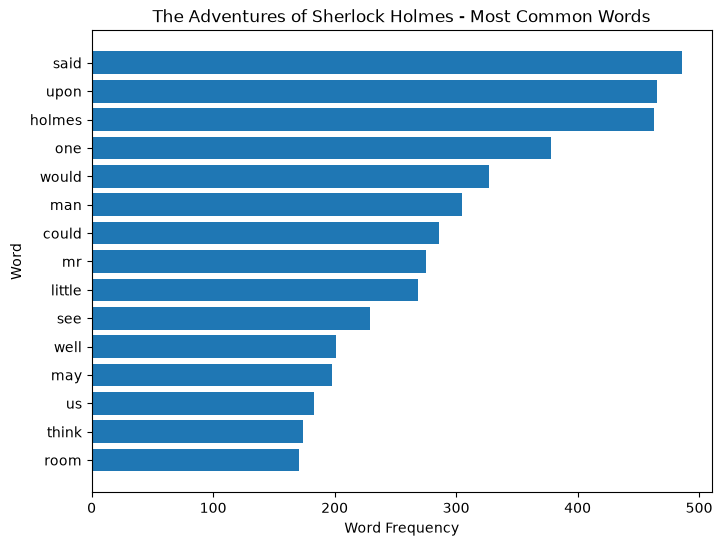

In [20]:
plot_top_words(
    "The Adventures of Sherlock Holmes - Most Common Words",
    doyle_book1
)

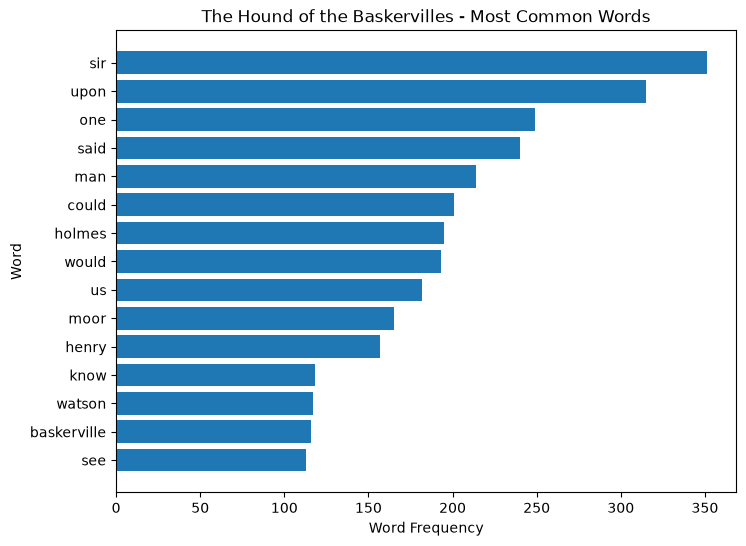

In [21]:
plot_top_words(
    "The Hound of the Baskervilles - Most Common Words",
    doyle_book2
)

### Initial Observation

The two Arthur Conan Doyle works share several frequently used words, including
"upon," "said," "one," "man," "could," and "would." This suggests that there
are some similarities in word usage between the two works.

However, some of the most frequent words are related to characters or settings,
such as "Holmes," "Watson," "Baskerville," and "moor." These words may reflect
the subject of each story rather than the author's general writing style.
Therefore, additional comparisons and normalized word frequencies are needed
before drawing conclusions about author-specific patterns.

## Comparison 2: Two Works by H. G. Wells

The second comparison examines word-frequency patterns in two works written by
H. G. Wells: *The Time Machine* and *The War of the Worlds*.

In [22]:
wells_book1 = book_results["The Time Machine"]["frequencies"]
wells_book2 = book_results["The War of the Worlds"]["frequencies"]

print("The Time Machine")
print(wells_book1.most_common(15))

print("\nThe War of the Worlds")
print(wells_book2.most_common(15))

The Time Machine
[('time', 208), ('one', 120), ('little', 114), ('upon', 113), ('came', 107), ('could', 92), ('machine', 89), ('said', 89), ('saw', 88), ('like', 74), ('seemed', 72), ('man', 71), ('thing', 66), ('traveller', 65), ('white', 61)]

The War of the Worlds
[('one', 204), ('upon', 172), ('martians', 166), ('said', 166), ('people', 159), ('came', 151), ('saw', 131), ('towards', 129), ('man', 127), ('time', 122), ('black', 122), ('could', 116), ('little', 112), ('men', 110), ('road', 105)]


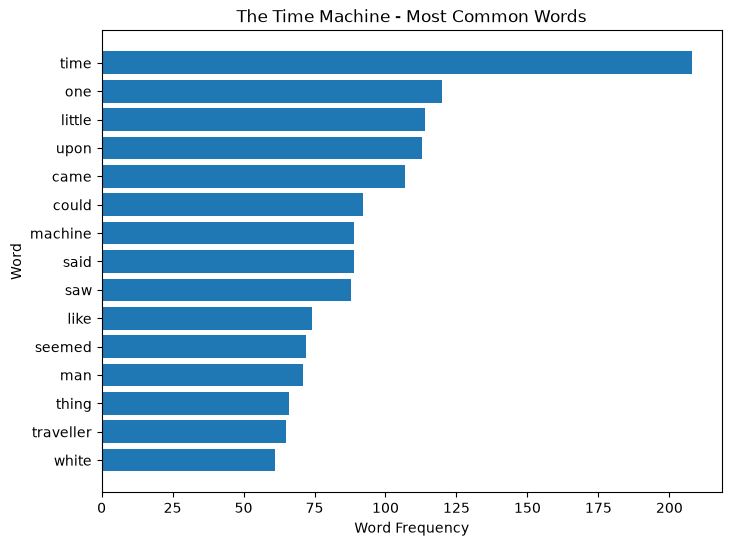

In [23]:
plot_top_words(
    "The Time Machine - Most Common Words",
    wells_book1
)

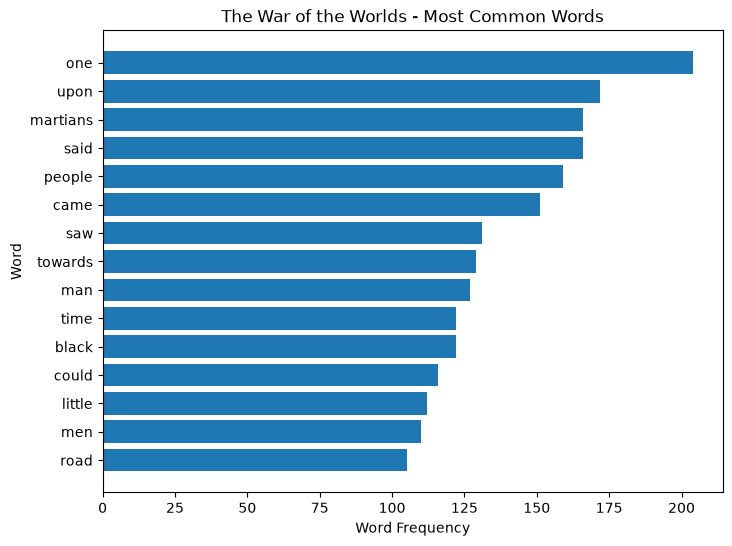

In [24]:
plot_top_words(
    "The War of the Worlds - Most Common Words",
    wells_book2
)

### Initial Observation

The two H. G. Wells works also share several frequently used words. Words such as
"one," "upon," "said," "came," "saw," "man," "time," "could," and "little"
appear frequently across both books.

There are also words that are strongly related to the subject of each book.
For example, "machine" and "traveller" appear frequently in *The Time Machine*,
while "Martians" appears frequently in *The War of the Worlds*. These words
likely reflect differences in story content rather than differences in writing style.

Because the books have different lengths, the next step is to compare normalized
word frequencies rather than relying only on raw word counts.

## Normalized Word Frequencies

The books have different total lengths, so raw word counts cannot be compared
directly. To make the comparison fairer, I will calculate the number of times
each word occurs per 10,000 regular words.

Normalized Frequency = (Word Count / Total Words) × 10,000

In [25]:
def normalized_frequency(word, book):
    count = book["frequencies"][word]
    total = book["total_words"]
    
    return (count / total) * 10000

In [26]:
word = "upon"

for title, data in book_results.items():
    freq = normalized_frequency(word, data)
    print(f"{title}: {freq:.2f} per 10,000 words")

Sherlock Holmes: 98.63 per 10,000 words
Hound of the Baskervilles: 117.43 per 10,000 words
The Time Machine: 72.02 per 10,000 words
The War of the Worlds: 57.37 per 10,000 words


In [27]:
comparison_words = [
    "upon",
    "said",
    "one",
    "man",
    "could",
    "would",
    "little",
    "see",
    "time",
    "came",
    "saw"
]

for word in comparison_words:
    print(f"\n{word.upper()}")
    
    for title, data in book_results.items():
        freq = normalized_frequency(word, data)
        print(f"{title}: {freq:.2f}")


UPON
Sherlock Holmes: 98.63
Hound of the Baskervilles: 117.43
The Time Machine: 72.02
The War of the Worlds: 57.37

SAID
Sherlock Holmes: 103.09
Hound of the Baskervilles: 89.47
The Time Machine: 56.72
The War of the Worlds: 55.37

ONE
Sherlock Holmes: 80.18
Hound of the Baskervilles: 92.83
The Time Machine: 76.48
The War of the Worlds: 68.04

MAN
Sherlock Holmes: 64.70
Hound of the Baskervilles: 79.78
The Time Machine: 45.25
The War of the Worlds: 42.36

COULD
Sherlock Holmes: 60.67
Hound of the Baskervilles: 74.93
The Time Machine: 58.63
The War of the Worlds: 38.69

WOULD
Sherlock Holmes: 69.36
Hound of the Baskervilles: 71.95
The Time Machine: 38.24
The War of the Worlds: 34.02

LITTLE
Sherlock Holmes: 57.06
Hound of the Baskervilles: 21.25
The Time Machine: 72.65
The War of the Worlds: 37.36

SEE
Sherlock Holmes: 48.57
Hound of the Baskervilles: 42.13
The Time Machine: 28.68
The War of the Worlds: 23.35

TIME
Sherlock Holmes: 32.03
Hound of the Baskervilles: 32.06
The Time Machin

## Comparison 3: Arthur Conan Doyle vs. H. G. Wells

After examining consistency within each author's works, I will combine the two
books from each author and compare their overall word-use patterns.

This comparison will help identify words that appear more frequently in the
selected works of Arthur Conan Doyle and words that appear more frequently in
the selected works of H. G. Wells.

In [28]:
doyle_titles = [
    "Sherlock Holmes",
    "Hound of the Baskervilles"
]

wells_titles = [
    "The Time Machine",
    "The War of the Worlds"
]

In [29]:
doyle_freq = Counter()
wells_freq = Counter()

doyle_total = 0
wells_total = 0

for title in doyle_titles:
    doyle_freq.update(book_results[title]["frequencies"])
    doyle_total += book_results[title]["total_words"]

for title in wells_titles:
    wells_freq.update(book_results[title]["frequencies"])
    wells_total += book_results[title]["total_words"]

print("Arthur Conan Doyle total words:", doyle_total)
print("H. G. Wells total words:", wells_total)

Arthur Conan Doyle total words: 73968
H. G. Wells total words: 45672


In [30]:
print("Arthur Conan Doyle")
print(doyle_freq.most_common(20))

print("\nH. G. Wells")
print(wells_freq.most_common(20))

Arthur Conan Doyle
[('upon', 780), ('said', 726), ('holmes', 658), ('one', 627), ('would', 520), ('man', 519), ('could', 487), ('sir', 429), ('us', 365), ('see', 342), ('mr', 338), ('little', 326), ('well', 312), ('may', 301), ('know', 288), ('think', 264), ('come', 249), ('must', 248), ('time', 237), ('two', 228)]

H. G. Wells
[('time', 330), ('one', 324), ('upon', 285), ('came', 258), ('said', 255), ('little', 226), ('saw', 219), ('could', 208), ('people', 205), ('man', 198), ('towards', 176), ('like', 169), ('martians', 166), ('seemed', 164), ('would', 162), ('black', 152), ('still', 149), ('went', 148), ('night', 141), ('way', 138)]


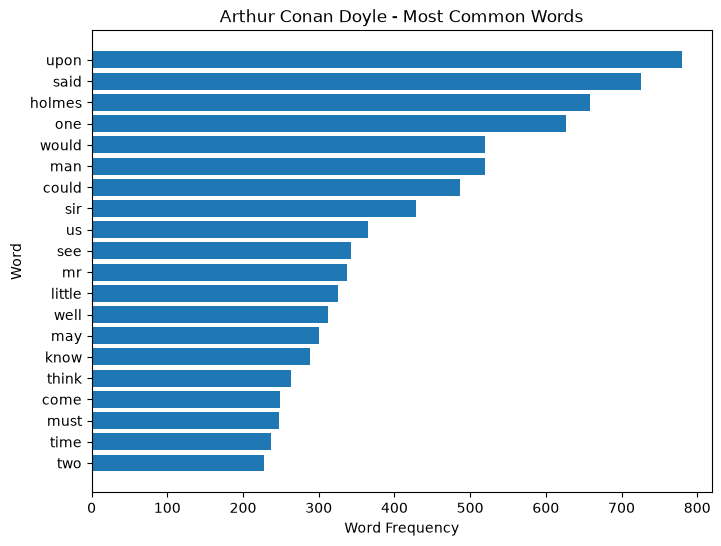

In [31]:
plot_top_words(
    "Arthur Conan Doyle - Most Common Words",
    doyle_freq,
    20
)

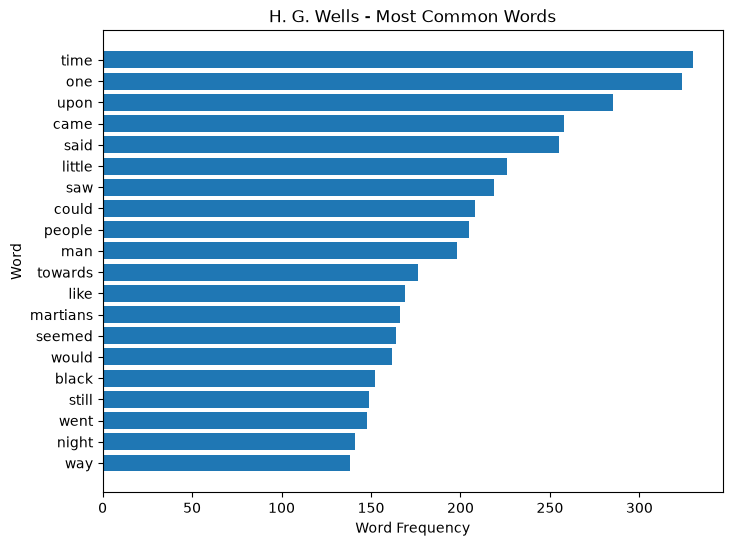

In [32]:
plot_top_words(
    "H. G. Wells - Most Common Words",
    wells_freq,
    20
)

In [33]:
all_words = set(doyle_freq.keys()) | set(wells_freq.keys())

differences = []

for word in all_words:
    
    doyle_normalized = (doyle_freq[word] / doyle_total) * 10000
    wells_normalized = (wells_freq[word] / wells_total) * 10000
    
    difference = doyle_normalized - wells_normalized
    
    differences.append(
        (word, doyle_normalized, wells_normalized, difference)
    )

In [34]:
differences_sorted = sorted(
    differences,
    key=lambda x: x[3],
    reverse=True
)

In [35]:
print("Words used more frequently by Arthur Conan Doyle:\n")

for word, doyle_f, wells_f, diff in differences_sorted[:20]:
    print(
        f"{word:15} Doyle: {doyle_f:7.2f} "
        f"Wells: {wells_f:7.2f} "
        f"Difference: {diff:7.2f}"
    )

Words used more frequently by Arthur Conan Doyle:

holmes          Doyle:   88.96 Wells:    0.00 Difference:   88.96
sir             Doyle:   58.00 Wells:    1.97 Difference:   56.03
mr              Doyle:   45.70 Wells:    0.22 Difference:   45.48
upon            Doyle:  105.45 Wells:   62.40 Difference:   43.05
said            Doyle:   98.15 Wells:   55.83 Difference:   42.32
would           Doyle:   70.30 Wells:   35.47 Difference:   34.83
well            Doyle:   42.18 Wells:   13.79 Difference:   28.39
man             Doyle:   70.17 Wells:   43.35 Difference:   26.81
watson          Doyle:   26.77 Wells:    0.00 Difference:   26.77
shall           Doyle:   28.12 Wells:    3.28 Difference:   24.84
may             Doyle:   40.69 Wells:   17.08 Difference:   23.61
know            Doyle:   38.94 Wells:   15.33 Difference:   23.61
yes             Doyle:   25.01 Wells:    1.97 Difference:   23.04
henry           Doyle:   22.58 Wells:    0.00 Difference:   22.58
moor            Doyle:   

In [36]:
print("Words used more frequently by H. G. Wells:\n")

for word, doyle_f, wells_f, diff in differences_sorted[-20:][::-1]:
    print(
        f"{word:15} Doyle: {doyle_f:7.2f} "
        f"Wells: {wells_f:7.2f} "
        f"Difference: {diff:7.2f}"
    )

Words used more frequently by H. G. Wells:

time            Doyle:   32.04 Wells:   72.25 Difference:  -40.21
people          Doyle:    6.35 Wells:   44.89 Difference:  -38.53
martians        Doyle:    0.00 Wells:   36.35 Difference:  -36.35
towards         Doyle:    5.81 Wells:   38.54 Difference:  -32.72
saw             Doyle:   20.28 Wells:   47.95 Difference:  -27.67
machine         Doyle:    2.16 Wells:   29.34 Difference:  -27.18
came            Doyle:   29.74 Wells:   56.49 Difference:  -26.75
seemed          Doyle:   14.20 Wells:   35.91 Difference:  -21.71
black           Doyle:   13.38 Wells:   33.28 Difference:  -19.90
men             Doyle:    7.30 Wells:   27.15 Difference:  -19.85
went            Doyle:   12.84 Wells:   32.40 Difference:  -19.56
brother         Doyle:    4.46 Wells:   23.21 Difference:  -18.75
pit             Doyle:    0.54 Wells:   18.83 Difference:  -18.29
martian         Doyle:    0.00 Wells:   18.17 Difference:  -18.17
across          Doyle:    8.92 W

### Author Comparison Results

After normalizing the frequencies per 10,000 words, noticeable differences appear
between the selected works of Arthur Conan Doyle and H. G. Wells.

Arthur Conan Doyle uses words such as "upon," "said," "would," "shall," "may,"
"know," and "think" more frequently in the selected works. For example, "upon"
appears approximately 105.45 times per 10,000 words in Doyle's books compared
with 62.40 times in Wells's books. Similarly, "would" appears about 70.30 times
per 10,000 words for Doyle compared with 35.47 for Wells.

H. G. Wells uses words such as "time," "people," "towards," "saw," "came,"
"seemed," and "went" more frequently. For example, "time" appears approximately
72.25 times per 10,000 words in Wells's books compared with 32.04 times in
Doyle's books.

Some of the largest differences are caused by story-specific words and character
names. Words such as "Holmes," "Watson," "Martians," and "machine" reflect the
content of the individual stories and should not automatically be interpreted
as evidence of an author's general writing style.

However, the differences among more general words suggest that measurable
word-use patterns do exist in these selected works.

## Comparison of Selected Words

To focus more on possible writing patterns rather than story-specific vocabulary,
I selected several general words that occur in both authors' works and compared
their normalized frequencies.

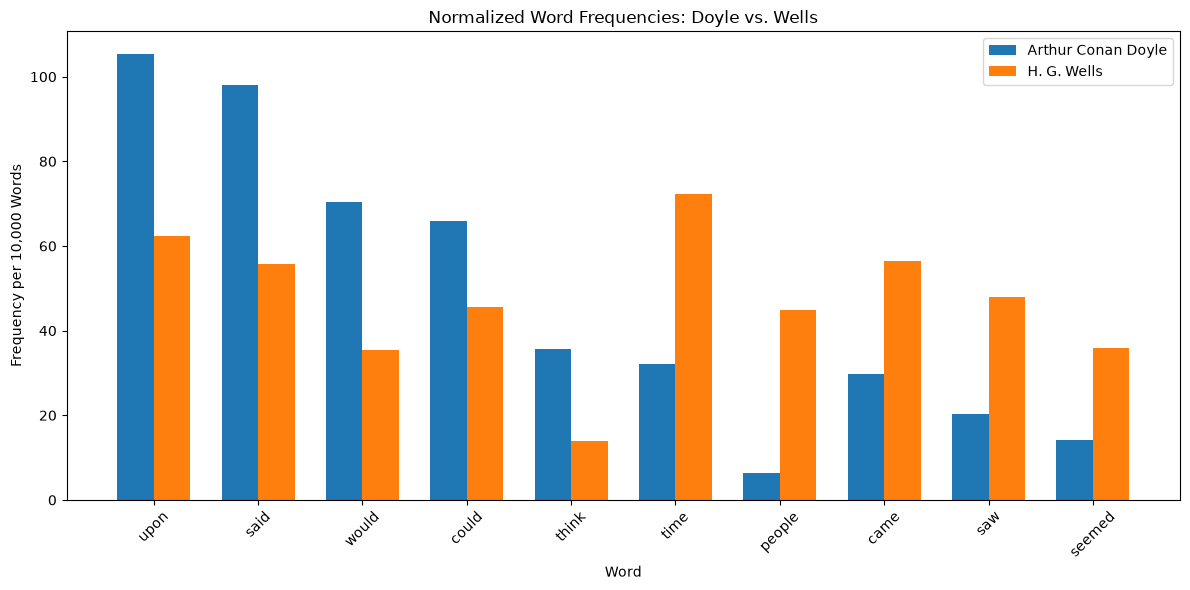

In [37]:
selected_words = [
    "upon",
    "said",
    "would",
    "could",
    "think",
    "time",
    "people",
    "came",
    "saw",
    "seemed"
]

doyle_values = []
wells_values = []

for word in selected_words:
    doyle_values.append((doyle_freq[word] / doyle_total) * 10000)
    wells_values.append((wells_freq[word] / wells_total) * 10000)

x = np.arange(len(selected_words))
width = 0.35

plt.figure(figsize=(12, 6))

plt.bar(x - width/2, doyle_values, width, label="Arthur Conan Doyle")
plt.bar(x + width/2, wells_values, width, label="H. G. Wells")

plt.xlabel("Word")
plt.ylabel("Frequency per 10,000 Words")
plt.title("Normalized Word Frequencies: Doyle vs. Wells")
plt.xticks(x, selected_words, rotation=45)
plt.legend()

plt.tight_layout()
plt.show()

### Observation

The normalized comparison shows that some general words have noticeably
different frequencies between the two authors. Doyle uses words such as
"upon," "said," and "would" more frequently, while Wells uses words such as
"time," "people," "came," "saw," and "seemed" more frequently.

These differences suggest that word-frequency patterns may provide measurable
traces of writing style. However, this analysis only considers four books, so
the results should not be treated as proof that these patterns will appear in
all works written by either author.

## Results

The analysis showed measurable differences in word-frequency patterns between
the selected works of Arthur Conan Doyle and H. G. Wells.

For Arthur Conan Doyle, words such as "upon," "said," "would," "could," and
"think" appeared more frequently after normalizing by the total number of words.

For H. G. Wells, words such as "time," "people," "came," "saw," and "seemed"
appeared more frequently.

For example, "upon" appeared approximately 105 times per 10,000 words in
Doyle's selected works compared with about 62 times per 10,000 words in Wells's
works. In contrast, "time" appeared about 72 times per 10,000 words in Wells's
works compared with about 32 times in Doyle's works.

The results also showed similarities between books written by the same author.
However, some frequently occurring words were clearly related to the stories
themselves, such as "Holmes," "Watson," "Martians," and "machine."

## Problems Encountered

One problem was that the four books have different lengths, which makes raw
word counts difficult to compare directly. I addressed this by calculating
normalized frequencies per 10,000 words.

Another issue was distinguishing between words that may reflect an author's
writing patterns and words that simply reflect the subject, characters, or
setting of a particular book. For example, words such as "Holmes," "Watson,"
"Martians," and "machine" occur frequently because they are important to the
stories.

I also had to clean the Project Gutenberg text before analysis by removing
headers, footers, punctuation, and common stop words.

## Limitations

This analysis only uses two books from each author, so the results cannot be
used to make conclusions about every work written by Arthur Conan Doyle or
H. G. Wells.

Word frequency alone also cannot determine with certainty who wrote a document.
Some differences may be caused by the subject of the books rather than the
author's writing style.

Therefore, the results provide evidence of measurable patterns in these
selected works, but they should not be treated as proof of authorship.

## New Ideas

This analysis generated several ideas for further investigation.

A larger study could include more books from each author to determine whether
the same word-frequency patterns remain consistent across additional works.

Another possibility would be to remove character names, locations, and other
story-specific vocabulary before comparing the authors.

Future analysis could also examine additional writing features such as sentence
length, vocabulary diversity, punctuation patterns, or the frequency of specific
function words.

These additional features could provide a more complete picture of differences
in writing style.

## Conclusion

The goal of this project was to investigate whether measurable word-frequency
patterns could be observed within and between works written by Arthur Conan
Doyle and H. G. Wells.

The results showed similarities between works written by the same author and
clear differences between the two authors for several commonly used words.
After normalizing frequencies to account for different book lengths, Doyle used
words such as "upon," "said," and "would" more frequently, while Wells used
words such as "time," "people," and "came" more frequently.

These findings suggest that word usage can leave measurable traces in written
text. However, because only four books were analyzed and some differences may
be related to story content, the results should be interpreted as evidence of
patterns in these selected works rather than proof of a general author-writing
signature.

# Extra Credit: Binomial Comparison of the Word "would"

For the extra-credit analysis, I selected the word **"would"**.

If each regular word in a book is treated as a trial, then the occurrence of
"would" can be modeled as a binomial event.

For each text:

p = N("would") / N(total regular words)

I will compare the estimated probability of using "would":

1. Between the two Arthur Conan Doyle books
2. Between the two H. G. Wells books
3. Between the combined works of Doyle and Wells

A two-proportion z-test will be used to determine whether the differences are
statistically significant.

In [38]:
import math

def two_proportion_z_test(count1, total1, count2, total2):
    
    p1 = count1 / total1
    p2 = count2 / total2

    # Pooled probability under the null hypothesis
    pooled_p = (count1 + count2) / (total1 + total2)

    # Standard error
    standard_error = math.sqrt(
        pooled_p * (1 - pooled_p) *
        ((1 / total1) + (1 / total2))
    )

    # Z statistic
    z = (p1 - p2) / standard_error

    # Two-tailed p-value
    p_value = math.erfc(abs(z) / math.sqrt(2))

    return p1, p2, z, p_value

In [39]:
word = "would"

doyle1 = book_results["Sherlock Holmes"]
doyle2 = book_results["Hound of the Baskervilles"]

count1 = doyle1["frequencies"][word]
count2 = doyle2["frequencies"][word]

p1, p2, z, p_value = two_proportion_z_test(
    count1,
    doyle1["total_words"],
    count2,
    doyle2["total_words"]
)

print("Arthur Conan Doyle: Same-Author Comparison")
print("-" * 50)
print(f"Sherlock Holmes: {count1} occurrences")
print(f"Probability: {p1:.6f}")
print()
print(f"Hound of the Baskervilles: {count2} occurrences")
print(f"Probability: {p2:.6f}")
print()
print(f"Z statistic: {z:.3f}")
print(f"P-value: {p_value:.6f}")

Arthur Conan Doyle: Same-Author Comparison
--------------------------------------------------
Sherlock Holmes: 327 occurrences
Probability: 0.006936

Hound of the Baskervilles: 193 occurrences
Probability: 0.007195

Z statistic: -0.405
P-value: 0.685406


In [40]:
wells1 = book_results["The Time Machine"]
wells2 = book_results["The War of the Worlds"]

count1 = wells1["frequencies"][word]
count2 = wells2["frequencies"][word]

p1, p2, z, p_value = two_proportion_z_test(
    count1,
    wells1["total_words"],
    count2,
    wells2["total_words"]
)

print("H. G. Wells: Same-Author Comparison")
print("-" * 50)
print(f"The Time Machine: {count1} occurrences")
print(f"Probability: {p1:.6f}")
print()
print(f"The War of the Worlds: {count2} occurrences")
print(f"Probability: {p2:.6f}")
print()
print(f"Z statistic: {z:.3f}")
print(f"P-value: {p_value:.6f}")

H. G. Wells: Same-Author Comparison
--------------------------------------------------
The Time Machine: 60 occurrences
Probability: 0.003824

The War of the Worlds: 102 occurrences
Probability: 0.003402

Z statistic: 0.720
P-value: 0.471600


In [41]:
doyle_would = doyle_freq[word]
wells_would = wells_freq[word]

p_doyle, p_wells, z, p_value = two_proportion_z_test(
    doyle_would,
    doyle_total,
    wells_would,
    wells_total
)

print("Arthur Conan Doyle vs. H. G. Wells")
print("-" * 50)

print(f"Doyle:")
print(f"  'would' count = {doyle_would}")
print(f"  Total words = {doyle_total}")
print(f"  Probability = {p_doyle:.6f}")
print(f"  Per 10,000 words = {p_doyle * 10000:.2f}")

print()

print(f"Wells:")
print(f"  'would' count = {wells_would}")
print(f"  Total words = {wells_total}")
print(f"  Probability = {p_wells:.6f}")
print(f"  Per 10,000 words = {p_wells * 10000:.2f}")

print()

print(f"Z statistic = {z:.3f}")
print(f"P-value = {p_value:.6f}")

if p_value < 0.05:
    print("Result: Statistically significant difference at alpha = 0.05.")
else:
    print("Result: No statistically significant difference at alpha = 0.05.")

Arthur Conan Doyle vs. H. G. Wells
--------------------------------------------------
Doyle:
  'would' count = 520
  Total words = 73968
  Probability = 0.007030
  Per 10,000 words = 70.30

Wells:
  'would' count = 162
  Total words = 45672
  Probability = 0.003547
  Per 10,000 words = 35.47

Z statistic = 7.774
P-value = 0.000000
Result: Statistically significant difference at alpha = 0.05.


## Extra Credit Results

I examined the word **"would"** using its
estimated probability of occurrence in each text.

### Arthur Conan Doyle

In *The Adventures of Sherlock Holmes*, "would" appeared 327 times with an
estimated probability of 0.006936.

In *The Hound of the Baskervilles*, it appeared 193 times with an estimated
probability of 0.007195.

The two-proportion test produced:

- Z statistic = -0.405
- P-value = 0.685406

Because the p-value is greater than 0.05, I did not find a statistically
significant difference in the use of "would" between the two Doyle books.

### H. G. Wells

In *The Time Machine*, "would" appeared 60 times with an estimated probability
of 0.003824.

In *The War of the Worlds*, it appeared 102 times with an estimated probability
of 0.003402.

The test produced:

- Z statistic = 0.720
- P-value = 0.471600

Again, the p-value is greater than 0.05, so I did not find a statistically
significant difference between the two Wells books.

### Arthur Conan Doyle vs. H. G. Wells

When the two books from each author were combined, the difference was much
larger.

- Doyle: 520 occurrences, or about 70.30 occurrences per 10,000 words
- Wells: 162 occurrences, or about 35.47 occurrences per 10,000 words

The comparison produced:

- Z statistic = 7.774
- P-value < 0.001

This indicates a statistically significant difference in the frequency of
"would" between the selected works of Arthur Conan Doyle and H. G. Wells.

Interestingly, the frequency of "would" was relatively consistent between two
works by the same author but substantially different between the two authors.
This provides evidence that the frequency of this particular word may represent
a measurable writing pattern in the selected texts. However, more books would
need to be analyzed before concluding that this pattern consistently identifies
either author's writing.